# aVANCE 4 OTROS MODELOS  Comparación de modelos para predecir `log_tdpa` —

**Objetivo:** comparar el Gradient Boosting ganador del Avance 3 con Random Forest, SVR, CatBoost y una GNN (GraphSAGE) manteniendo el mismo flujo de características y la misma validación espacial.

El preprocesamiento original ya **no está copiado aquí**: se importa desde `tdpa_comun.py`, extraído del notebook `Avance3.20(3).ipynb`. Coloca **ambos archivos** (`tdpa_comun.py` y este `.ipynb`) en `04_NOTEBOOKS` del proyecto. Este notebook no necesita ejecutar el notebook original; lee directamente el CSV procesado por el Avance 2.

**Referencia histórica:** GBoost + Filtro + PCA (sin recorte): RMSE log CV ≈ **0.7312**. Ese valor se muestra como referencia

## Paso 1 — Instalar dependencias (solo una vez)

En una celda aparte de VS Code ejecuta `%pip install catboost` y luego **reinicia el kernel**. Si no tienes PyTorch: `%pip install torch`.

También puedes instalar CatBoost desde tu entorno Conda en terminal: `conda install -c conda-forge catboost`. Para confirmar en qué Python se ejecuta el notebook: `import sys; print(sys.executable)`.


## Paso 2 — Importar librerías y funciones compartidas

In [ ]:
%pip install --upgrade catboost
%pip install --upgrade torch
from pathlib import Path
import sys
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics.pairwise import haversine_distances
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from threadpoolctl import threadpool_limits
from IPython.display import display

# Encontrar la raíz del repositorio sin necesidad de instalar tdpa_comun como paquete.
def buscar_raiz():
    for carpeta in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (carpeta / '03_PROCESSED').is_dir() and (carpeta / '04_NOTEBOOKS').is_dir():
            return carpeta
    raise FileNotFoundError('Abre VS Code en la raíz de tu repositorio (03_PROCESSED y 04_NOTEBOOKS)')

ROOT = buscar_raiz()
sys.path.insert(0, str(ROOT / '04_NOTEBOOKS'))
from tdpa_comun import (SEED, TARGET, PreparadorSeguro, preparar_datos,
                        construir_folds, detectar_log, invertir_log)

THREADS = 2
threadpool_limits(limits=THREADS)
np.random.seed(SEED)
FE_PATH = ROOT / '03_PROCESSED' / 'FE_TOP_Model_Table.csv'
OUT_DIR = ROOT / '06_RESULTS' / 'AVANCE4' / 'COMPARACION_SIMPLE'
OUT_DIR.mkdir(parents=True, exist_ok=True)
print('Datos:', FE_PATH)
print('Resultados:', OUT_DIR)


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.8/124.1 MB 4.7 MB/s eta 0:00:27
    --------------------------------------- 2.1/124.1 MB 5.1 MB/s eta 0:00:25
   - -------------------------------------- 3.4/124.1 MB 5.7 MB/s eta 0:00:22
   - -------------------------------------- 4.7/124.1 MB 6.0 MB/s eta 0:00:20
   -- ------------------------------------- 6.3/124.1 MB 6.1 MB/s eta 0:00:20
   -- ------------------------------------- 7.9/124.1 MB 6.4 MB/s eta 0:00:19
   --- ------------------------------------ 9.4/124.1 MB 6.6 MB/s eta 0:00:18
   --- ------------------------------------ 11.0/124.1 MB 6.9 MB/s eta 0:00:17
   ---- ----------------------------------- 12.6/124.1 MB 6.8 MB/s eta 0:00:17
   ---- ----------------------------------- 13.1/124.1 MB 6.4 MB/s eta 0:00:18
   ---- ----------------------------------- 14.4/124.1 MB 6.5 MB/s eta 0:00:17
   ----- ---------------------------------- 16.3/124.1 MB 6.7 MB/s 


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Datos: D:\TEC DE MONTERREY\maestria\Proyecto integrador\Equipo20_EnergyIntelligence\03_PROCESSED\FE_TOP_Model_Table.csv
Resultados: D:\TEC DE MONTERREY\maestria\Proyecto integrador\Equipo20_EnergyIntelligence\06_RESULTS\AVANCE3\COMPARACION_SIMPLE


## Paso 3 — Leer el CSV y reutilizar la validación

`preparar_datos` reserva el corredor de prueba y aplica la purga espacial; `construir_folds` prepara cinco particiones por bloque geográfico. Ambas funciones se importan del módulo común y **no se vuelven a escribir**. El preprocesamiento (`PreparadorSeguro`) seguirá ajustándose dentro de cada fold.


In [2]:
tabla, train_fe, test_fe = preparar_datos(FE_PATH)
transformacion, error_log = detectar_log(train_fe)
folds = construir_folds(train_fe)
print('Transformación objetivo:', transformacion)
display(pd.DataFrame([{'fold': f, 'n_train': len(tr), 'n_valid': len(va)}
                      for f, tr, va in folds]))


Tabla maestra (1075, 274) | train 703 | test externo 23 | purgados 349
Transformación objetivo: log


,fold,n_train,n_valid
0,1,127,141
1,2,150,141
2,3,197,141
3,4,105,140
4,5,138,140


## Paso 4 — Sustituir únicamente el estimador

Para los algoritmos tabulares, todos usan `PreparadorSeguro(modo="Filtro + PCA", recortar=False)`, igual que el mejor modelo original. Cambia solo el algoritmo final. No se ajustan hiperparámetros con el corredor externo.

**Nota:** en CatBoost aplicamos el mismo preparador y llamamos directamente al estimador para evitar incompatibilidades de integración en algunas versiones.


In [3]:
try:
    from catboost import CatBoostRegressor
except ImportError as e:
    raise ImportError("Falta CatBoost: ejecuta %pip install catboost en una celda") from e


def construir_modelo(nombre):
    estimadores = {
        "GBoost (anterior)": HistGradientBoostingRegressor(
            max_iter=150, learning_rate=0.05, early_stopping=False, random_state=SEED),
        "Random Forest": RandomForestRegressor(
            n_estimators=200, min_samples_leaf=3, random_state=SEED, n_jobs=THREADS),
        "SVR": SVR(kernel="rbf", C=10, epsilon=0.15, gamma="scale"),
        "CatBoost": CatBoostRegressor(
            iterations=300, depth=5, learning_rate=0.05, l2_leaf_reg=4,
            loss_function="RMSE", random_seed=SEED, thread_count=THREADS, verbose=False),
    }
    return Pipeline([
        ("prep", PreparadorSeguro(modo="Filtro + PCA", recortar=False)),
        ("modelo", estimadores[nombre]),
    ])

MODELOS = ["GBoost (anterior)", "Random Forest", "SVR", "CatBoost", "GNN (GraphSAGE)"]
print("Modelos a evaluar:", ", ".join(MODELOS))

Modelos a evaluar: GBoost (anterior), Random Forest, SVR, CatBoost, GNN (GraphSAGE)


## Paso 5 — GNN introductoria

GraphSAGE requiere relaciones entre nodos; aquí conectamos los cinco sitios más cercanos usando sus coordenadas. No representa todavía la conectividad real de las carreteras. Para reducir fuga de información, cada fold usa únicamente nodos de entrenamiento como vecinos de las observaciones de validación; las etiquetas de validación no entran al entrenamiento.


In [4]:
try:
    import torch
    from torch import nn
except ImportError as e:
    raise ImportError("Falta PyTorch: ejecuta %pip install torch en una celda") from e

torch.set_num_threads(THREADS)


def matriz_vecinos(coord_train, coord_nuevos=None, k=5):
    """Fila i = promedio de sus vecinos; nuevos nodos reciben mensajes SOLO de train."""
    geo_tr = np.radians(np.asarray(coord_train, dtype=float))
    dist_tr = haversine_distances(geo_tr, geo_tr)
    np.fill_diagonal(dist_tr, np.inf)
    k = min(k, len(geo_tr)-1)
    if k < 1:
        raise ValueError("La GNN necesita al menos dos sitios de entrenamiento")
    indices_tr = np.argsort(dist_tr, axis=1)[:, :k]
    n = len(geo_tr)
    A = np.zeros((n, n), dtype=np.float32)
    A[np.arange(n)[:, None], indices_tr] = 1.0 / k
    if coord_nuevos is None:
        return torch.tensor(A)

    geo_nuevos = np.radians(np.asarray(coord_nuevos, dtype=float))
    dist_nuevos = haversine_distances(geo_nuevos, geo_tr)
    indices_nuevos = np.argsort(dist_nuevos, axis=1)[:, :k]
    A_todos = np.zeros((n + len(geo_nuevos), n + len(geo_nuevos)), dtype=np.float32)
    A_todos[:n, :n] = A
    A_todos[n + np.arange(len(geo_nuevos))[:, None], indices_nuevos] = 1.0 / k
    return torch.tensor(A_todos)


class GraphSAGE(nn.Module):
    """Dos capas: atributos propios + promedio de atributos de vecinos."""
    def __init__(self, n_features, ocultas=32):
        super().__init__()
        self.capa1 = nn.Linear(2 * n_features, ocultas)
        self.capa2 = nn.Linear(2 * ocultas, 1)
        self.dropout = nn.Dropout(0.15)

    def forward(self, X, A):
        h = torch.relu(self.capa1(torch.cat([X, A @ X], dim=1)))
        h = self.dropout(h)
        return self.capa2(torch.cat([h, A @ h], dim=1)).flatten()


def predecir_gnn(X_train, y_train, geo_train, X_valid, geo_valid, epocas=150):
    """Una GNN nueva por fold, sin targets ni aristas entrantes desde validación a train."""
    torch.manual_seed(SEED)
    X_tr = torch.tensor(np.asarray(X_train, dtype=np.float32))
    X_va = torch.tensor(np.asarray(X_valid, dtype=np.float32))
    A_train = matriz_vecinos(geo_train)
    A_todos = matriz_vecinos(geo_train, geo_valid)
    y = np.asarray(y_train, dtype=np.float32)
    media, escala = float(y.mean()), float(max(y.std(), 1e-6))
    y_normalizada = torch.tensor((y - media) / escala)

    red = GraphSAGE(n_features=X_tr.shape[1])
    optimizador = torch.optim.Adam(red.parameters(), lr=0.01, weight_decay=0.001)
    for _ in range(epocas):
        red.train()
        optimizador.zero_grad()
        pred = red(X_tr, A_train)
        error = nn.functional.mse_loss(pred, y_normalizada)
        error.backward()
        optimizador.step()

    red.eval()
    with torch.no_grad():
        pred_train = red(X_tr, A_train).numpy() * escala + media
        pred_valid = red(torch.cat([X_tr, X_va]), A_todos).numpy()[-len(X_va):] * escala + media
    return pred_train, pred_valid

## Paso 6 — Entrenar y evaluar sobre los mismos cinco folds

Para cada algoritmo entrenamos desde cero en cada fold. Calculamos métricas tanto de entrenamiento como de validación, en escala `log_tdpa` y en vehículos/día. La selección principal se hace por **RMSE log de validación espacial**.


In [5]:
def evaluar_prediccion(reales, pred_log, modo_log):
    y = reales[TARGET].to_numpy(float)
    tdpa_real = reales["tdpa"].to_numpy(float)
    tdpa_pred = np.maximum(0, invertir_log(np.asarray(pred_log, dtype=float), modo_log))
    return {
        "rmse_log": np.sqrt(mean_squared_error(y, pred_log)),
        "mae_log": mean_absolute_error(y, pred_log),
        "r2_log": r2_score(y, pred_log),
        "mae_veh_dia": mean_absolute_error(tdpa_real, tdpa_pred),
        "rmse_veh_dia": np.sqrt(mean_squared_error(tdpa_real, tdpa_pred)),
        "wape_pct": 100 * np.abs(tdpa_real - tdpa_pred).sum() / np.abs(tdpa_real).sum(),
    }


def evaluar_modelos(datos, folds):
    filas, predicciones = [], []
    for nombre in MODELOS:
        print(f"Entrenando: {nombre}")
        for fold, idx_tr, idx_va in folds:
            tr, va = datos.loc[idx_tr], datos.loc[idx_va]
            tiempo = perf_counter()
            if nombre == "GNN (GraphSAGE)":
                prep = PreparadorSeguro(modo="Filtro + PCA", recortar=False)
                X_tr = prep.fit_transform(tr, tr[TARGET])
                X_va = prep.transform(va)
                p_tr, p_va = predecir_gnn(
                    X_tr, tr[TARGET], tr[["lat", "lon"]], X_va, va[["lat", "lon"]])
            elif nombre == "CatBoost":
                # Algunas combinaciones CatBoost/scikit-learn no permiten Pipeline.predict.
                # Aplicamos el MISMO preprocesador, pero llamamos al estimador directamente.
                pipeline = construir_modelo(nombre)
                prep = pipeline.named_steps["prep"]
                X_tr = prep.fit_transform(tr, tr[TARGET])
                X_va = prep.transform(va)
                modelo = pipeline.named_steps["modelo"]
                modelo.fit(X_tr, tr[TARGET])
                p_tr, p_va = modelo.predict(X_tr), modelo.predict(X_va)
            else:
                pipeline = construir_modelo(nombre)
                pipeline.fit(tr, tr[TARGET])
                p_tr = pipeline.predict(tr)
                p_va = pipeline.predict(va)
            segundos = perf_counter() - tiempo
            for conjunto, reales, estimados in [("train", tr, p_tr), ("valid", va, p_va)]:
                filas.append({"modelo": nombre, "fold": fold, "conjunto": conjunto,
                              "n_sitios": len(reales), "tiempo_seg": segundos,
                              **evaluar_prediccion(reales, estimados, transformacion)})
            predicciones.extend({"modelo": nombre, "fold": fold, "site_id": site,
                                  "real_log": float(real), "pred_log": float(pred)}
                                 for site, real, pred in zip(va.site_id, va[TARGET], p_va))
            print(f"  Fold {fold}: RMSE valid = {filas[-1]['rmse_log']:.4f}")
    return pd.DataFrame(filas), pd.DataFrame(predicciones)

metricas_folds, predicciones_cv = evaluar_modelos(train_fe, folds)
metricas_folds.to_csv(OUT_DIR / "metricas_por_fold.csv", index=False, encoding="utf-8-sig")
predicciones_cv.to_csv(OUT_DIR / "predicciones_cv.csv", index=False, encoding="utf-8-sig")
print("Evaluación terminada. Resultados guardados en:", OUT_DIR)

Entrenando: GBoost (anterior)
  Fold 1: RMSE valid = 0.6391
  Fold 2: RMSE valid = 0.7495
  Fold 3: RMSE valid = 0.7188
  Fold 4: RMSE valid = 0.7881
  Fold 5: RMSE valid = 0.7606
Entrenando: Random Forest
  Fold 1: RMSE valid = 0.6421
  Fold 2: RMSE valid = 0.7820
  Fold 3: RMSE valid = 0.7031
  Fold 4: RMSE valid = 0.7171
  Fold 5: RMSE valid = 0.8120
Entrenando: SVR
  Fold 1: RMSE valid = 0.7336
  Fold 2: RMSE valid = 0.8962
  Fold 3: RMSE valid = 0.7759
  Fold 4: RMSE valid = 0.8612
  Fold 5: RMSE valid = 0.8049
Entrenando: CatBoost
  Fold 1: RMSE valid = 0.6762
  Fold 2: RMSE valid = 0.7758
  Fold 3: RMSE valid = 0.6974
  Fold 4: RMSE valid = 0.8007
  Fold 5: RMSE valid = 0.8471
Entrenando: GNN (GraphSAGE)
  Fold 1: RMSE valid = 1.0028
  Fold 2: RMSE valid = 0.8105
  Fold 3: RMSE valid = 0.9641
  Fold 4: RMSE valid = 0.9079
  Fold 5: RMSE valid = 0.9732
Evaluación terminada. Resultados guardados en: D:\TEC DE MONTERREY\maestria\Proyecto integrador\Equipo20_EnergyIntelligence\06_RE

## Paso 7 — Comparación conjunta

El valor `0.7312` del notebook anterior aparece como referencia histórica, pero la decisión se toma con los resultados recalculados bajo los mismos folds. Un RMSE de entrenamiento mucho menor que el de validación es señal de posible sobreajuste.


In [6]:
valid = metricas_folds.query("conjunto == 'valid'")
entrenamiento = metricas_folds.query("conjunto == 'train'")
ranking = valid.groupby("modelo").agg(
    rmse_valid=("rmse_log", "mean"),
    sd_rmse=("rmse_log", "std"),
    mae_valid=("mae_log", "mean"),
    r2_valid=("r2_log", "mean"),
    mae_veh_dia=("mae_veh_dia", "mean"),
    rmse_veh_dia=("rmse_veh_dia", "mean"),
    wape_pct=("wape_pct", "mean"),
    tiempo_promedio_s=("tiempo_seg", "mean"),
).join(entrenamiento.groupby("modelo")["rmse_log"].mean().rename("rmse_train"))
ranking["brecha_rmse"] = ranking["rmse_valid"] - ranking["rmse_train"]
ranking = ranking.sort_values("rmse_valid")
ranking.to_csv(OUT_DIR / "ranking_modelos.csv", encoding="utf-8-sig")
display(ranking.round(4))

rmse_nuevo_gboost = float(ranking.loc["GBoost (anterior)", "rmse_valid"])
print(f"GBoost histórico: 0.7312 | GBoost reproducido: {rmse_nuevo_gboost:.4f}")
if abs(rmse_nuevo_gboost - 0.7312) > 0.01:
    print("Advertencia: revisa versión de librerías, datos FE y orden de las particiones.")
print("Mejor modelo por validación espacial:", ranking.index[0])
mejor_rmse = float(ranking.iloc[0]["rmse_valid"])
mejora = 100 * (rmse_nuevo_gboost - mejor_rmse) / rmse_nuevo_gboost
print(f"Cambio de RMSE frente al GBoost de esta corrida: {mejora:+.2f}% de reducción")

,rmse_valid,sd_rmse,mae_valid,r2_valid,mae_veh_dia,rmse_veh_dia,wape_pct,tiempo_promedio_s,rmse_train,brecha_rmse
modelo,,,,,,,,,,
GBoost (anterior),0.7312,0.0572,0.5689,0.5439,10286.9229,20737.4006,52.9295,1.3704,0.3234,0.4079
Random Forest,0.7312,0.0671,0.5636,0.5453,10107.3408,20552.1241,51.8512,1.8738,0.3537,0.3775
CatBoost,0.7594,0.0714,0.5864,0.5112,10644.1047,21711.8012,54.5842,2.8308,0.1917,0.5678
SVR,0.8144,0.0651,0.6302,0.4375,11115.4453,21404.2227,57.1183,1.1405,0.3515,0.4629
GNN (GraphSAGE),0.9317,0.0760,0.7170,0.2516,13528.4484,25037.5334,69.6061,2.0569,0.1802,0.7515


GBoost histórico: 0.7312 | GBoost reproducido: 0.7312
Mejor modelo por validación espacial: GBoost (anterior)
Cambio de RMSE frente al GBoost de esta corrida: +0.00% de reducción


## Paso 8 — Gráficas de rendimiento y estabilidad

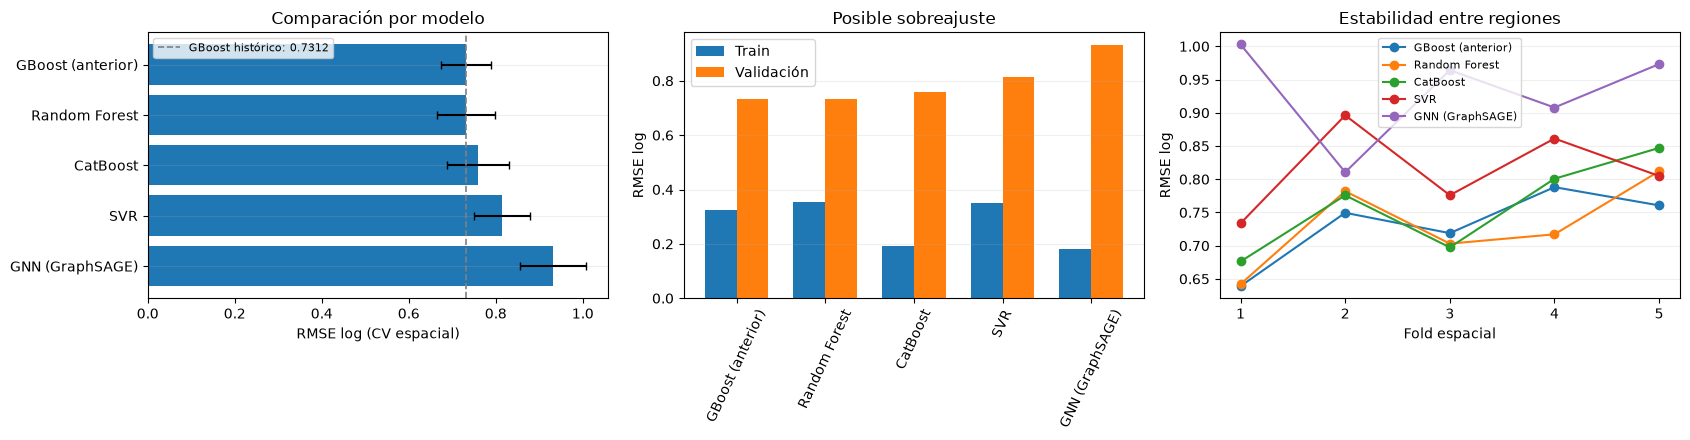

In [7]:
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))
orden = ranking.index.to_list()
pos = np.arange(len(orden))
ejes[0].barh(pos, ranking.loc[orden, "rmse_valid"], xerr=ranking.loc[orden, "sd_rmse"], capsize=3)
ejes[0].axvline(0.7312, color="gray", ls="--", lw=1.2, label="GBoost histórico: 0.7312")
ejes[0].set(yticks=pos, yticklabels=orden, xlabel="RMSE log (CV espacial)", title="Comparación por modelo")
ejes[0].legend(fontsize=8)
ejes[0].invert_yaxis()

ejes[1].bar(pos-0.18, ranking.loc[orden, "rmse_train"], width=0.36, label="Train")
ejes[1].bar(pos+0.18, ranking.loc[orden, "rmse_valid"], width=0.36, label="Validación")
ejes[1].set(xticks=pos, xticklabels=orden, ylabel="RMSE log", title="Posible sobreajuste")
ejes[1].tick_params(axis="x", rotation=65)
ejes[1].legend()

for nombre in orden:
    z = valid.loc[valid.modelo.eq(nombre)].sort_values("fold")
    ejes[2].plot(z.fold, z.rmse_log, marker="o", label=nombre)
ejes[2].set(xlabel="Fold espacial", ylabel="RMSE log", title="Estabilidad entre regiones", xticks=range(1,6))
ejes[2].legend(fontsize=8)
for eje in ejes:
    eje.grid(alpha=0.2, axis="y")
fig.tight_layout()
fig.savefig(OUT_DIR / "comparacion_modelos.png", dpi=160, bbox_inches="tight")
plt.show()